[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch54_LabCh54_Graph_Networks.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 54: Graph Neural Networks** (Part XII: Other Shapes of Data).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=54](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=54)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch54 - Graph networks by hand and in Keras
## Pass messages along the edges of a graph, then watch what two labelled nodes can do

This lab goes with **Chapter 54** of *The Why Book of Deep Learning, Part 2*.

A graph is a set of things (nodes) and the links between them (edges). A graph network gives every node a
vector and lets each node update its vector from its neighbours' vectors. In this lab you do one round of
that by hand on five nodes, turn the round into one matrix product, write a two-layer graph convolution
network (GCN, 2016/17) in Keras, and train it on two graphs that are made inside the notebook.

| Graph | Nodes | Edges | Node features | Task |
|---|---|---|---|---|
| Toy | 5 | 5 | one number each | message passing by hand |
| Zachary's karate club (1977) | 34 | 78 | none: each member is a one-hot row | which club did each member join? Two labels given |
| Three communities (synthetic) | 600 | about 2,500 | 16 noisy numbers | which community? 30 labels given |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Turn an edge list into an adjacency matrix and read degrees from it | Steps 2 and 7 |
| Do one round of message passing by hand: send, aggregate, update | Step 3 |
| Say what sum, mean and max can and cannot tell apart | Step 4 |
| Build the normalised adjacency matrix and say why it has self-loops and a degree normalisation | Steps 5 and 6 |
| Write a GCN layer as two matrix products and count its parameters before Keras does | Step 8 |
| Train with a handful of labelled nodes and compare with a model that ignores the edges | Steps 9 to 13 |
| Measure over-smoothing, and show that a skip connection helps | Steps 14 to 16 |
| Test permutation equivariance, and run a trained model on a graph it has never seen | Steps 17 and 18 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two minutes on a laptop CPU. No GPU and no downloads: every graph is made here.

> **Honest scale:** these are miniatures. The largest graph has 600 nodes and is generated by a formula that
> was chosen so that the features are weak and the edges are informative. Real graphs have thousands to
> billions of nodes, and their edges are not always this helpful. Every accuracy printed here is a number
> for comparing the runs in this notebook with each other.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, ops

SEED = 54
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - A graph is an edge list, or an adjacency matrix

Five people, A to E. A, B and C all know each other. C also knows D, and D knows E. That is the whole graph:

```
  A --- B
   \   /
     C --- D --- E
```

The **edge list** writes one pair per link. The **adjacency matrix** `A` is a 5 × 5 table with a 1 in row i,
column j when i and j are linked. Friendship has no direction, so every edge is entered both ways.

> **Predict:** how many 1s will the matrix hold for 5 edges? What will its diagonal be? Which node has the
> most neighbours?

In [2]:
names = ["A", "B", "C", "D", "E"]
toy_edges = [(0, 1), (0, 2), (1, 2), (2, 3), (3, 4)]

def adjacency(edges, n):
    """Edge list -> symmetric adjacency matrix of 0s and 1s."""
    A = np.zeros((n, n), dtype="float32")
    for i, j in edges:
        A[i, j] = 1.0
        A[j, i] = 1.0
    return A

A_toy = adjacency(toy_edges, 5)
print(A_toy.astype(int))
print("ones in the matrix:", int(A_toy.sum()), " (2 per edge)")
print("degree of each node:", dict(zip(names, A_toy.sum(1).astype(int))))
print("symmetric:", bool((A_toy == A_toy.T).all()), "| diagonal:", np.diag(A_toy).astype(int))

[[0 1 1 0 0]
 [1 0 1 0 0]
 [1 1 0 1 0]
 [0 0 1 0 1]
 [0 0 0 1 0]]
ones in the matrix: 10  (2 per edge)
degree of each node: {'A': np.int64(2), 'B': np.int64(2), 'C': np.int64(3), 'D': np.int64(2), 'E': np.int64(1)}
symmetric: True | diagonal: [0 0 0 0 0]


### Why we see this

Each undirected edge is written twice, so 5 edges give 10 ones. A row's sum is that node's **degree**, its
number of neighbours: C has 3, E has 1. The diagonal is zero because nobody is listed as their own neighbour.
Remember that zero diagonal. It causes a bug in Step 5.

The matrix is a table about pairs of nodes. It is not a picture: list the same five people in a different
order and you get a different-looking matrix for the very same graph (Step 17).

---
## Step 3 - One round of message passing, by hand

Give every node one number (its feature): A = 3, B = 6, C = 0, D = 9, E = 3. One round of message passing is
three verbs, done by every node at once:

1. **send**: each node sends its number to its neighbours;
2. **aggregate**: each node combines what arrived, here by taking the **mean** of its neighbours' numbers
   and its own;
3. **update**: the result becomes the node's new number. (A real layer also multiplies by weights here.)

> **Predict:** work out the new number for C (it hears from A, B, D and itself) and for E (it hears from D
> and itself) before running the cell.

In [3]:
x_toy = np.array([3.0, 6.0, 0.0, 9.0, 3.0], dtype="float32")

neighbours = {i: [j for j in range(5) if A_toy[i, j] == 1] for i in range(5)}
new_x = np.zeros(5, dtype="float32")
for i in range(5):
    inbox = [x_toy[j] for j in neighbours[i]] + [x_toy[i]]      # messages from neighbours, plus itself
    new_x[i] = np.mean(inbox)                                    # aggregate with the mean
    who = "+".join(names[j] for j in neighbours[i]) + "+" + names[i]
    print(f"{names[i]}: hears {who:8s} = {[float(v) for v in inbox]}  ->  mean {new_x[i]:.2f}")
print("before:", x_toy)
print("after :", new_x)

A: hears B+C+A    = [6.0, 0.0, 3.0]  ->  mean 3.00
B: hears A+C+B    = [3.0, 0.0, 6.0]  ->  mean 3.00
C: hears A+B+D+C  = [3.0, 6.0, 9.0, 0.0]  ->  mean 4.50
D: hears C+E+D    = [0.0, 3.0, 9.0]  ->  mean 4.00
E: hears D+E      = [9.0, 3.0]  ->  mean 6.00
before: [3. 6. 0. 9. 3.]
after : [3.  3.  4.5 4.  6. ]


### Why we see this

C averages 3, 6, 9 and its own 0 and gets 4.5. E averages 9 and 3 and gets 6. Every node now carries a
little of its neighbourhood. A and B end on the same value, 3.0, and that is no accident: they have exactly
the same neighbourhood (each other, and C), so nothing in this graph can tell them apart except their own
starting numbers.

Notice also what E knows: only D's old number and its own. It has not heard from C yet. Reach grows one hop
per round (Step 6).

---
## Step 4 - Sum, mean or max: what each one can tell apart

The aggregation must not depend on the order in which the neighbours are listed, because a graph has no
first neighbour. Sum, mean and max all qualify. They do not see the same things.

> **Predict:** a node hears {2, 2}. Another hears {2, 2, 2, 2}. A third hears {1, 3}. Which of sum, mean and
> max can tell the first from the second? The first from the third?

In [4]:
inboxes = {"{2, 2}": [2, 2], "{2, 2, 2, 2}": [2, 2, 2, 2], "{1, 3}": [1, 3], "{3, 1}": [3, 1]}
print(f"{'inbox':14s} {'sum':>5s} {'mean':>6s} {'max':>5s}")
for name, v in inboxes.items():
    print(f"{name:14s} {np.sum(v):5.0f} {np.mean(v):6.1f} {np.max(v):5.0f}")

inbox            sum   mean   max
{2, 2}             4    2.0     2
{2, 2, 2, 2}       8    2.0     2
{1, 3}             4    2.0     3
{3, 1}             4    2.0     3


### Why we see this

| Pair | sum | mean | max |
|---|---|---|---|
| {2, 2} against {2, 2, 2, 2} | different (4, 8) | same (2) | same (2) |
| {2, 2} against {1, 3} | same (4) | same (2) | different (2, 3) |
| {1, 3} against {3, 1} | same | same | same: order never matters |

The mean forgets **how many** neighbours spoke. The max forgets everything except the loudest. The sum keeps
the count, which is why sum-based layers (GIN, 2018/19) can tell more neighbourhoods apart. Its price is that
a node with a thousand neighbours gets a number a thousand times bigger (Step 19). No single choice sees
everything: here sum and mean both miss the second pair.

---
## Step 5 - The same round as one matrix product

Doing the loop of Step 3 for every node is a matrix product. Row i of `A @ x` adds up the numbers of i's
neighbours. Two repairs turn that into the mean of Step 3:

- **self-loops**: add the identity matrix, so each node also hears itself: `A + I`;
- **normalise**: divide each row by its sum (the degree + 1), so the row is an average, not a total.

> **Predict:** what does plain `A @ x` give for node E, whose own number is 3 and whose only neighbour D
> holds 9? Is E's own number in the answer at all?

In [5]:
I5 = np.eye(5, dtype="float32")
print("A @ x          :", A_toy @ x_toy, " <- sums, and each node ignores itself")
print("(A + I) @ x    :", (A_toy + I5) @ x_toy, " <- sums, self included")

def mean_adj(A, self_loops=True):
    """Row-normalised adjacency: row i averages over i's neighbours (and i itself)."""
    A1 = A + np.eye(len(A), dtype="float32") if self_loops else A.copy()
    return (A1 / np.maximum(A1.sum(1, keepdims=True), 1.0)).astype("float32")

P_toy = mean_adj(A_toy)
print("row-normalised (A + I):")
print(P_toy)
print("P @ x          :", P_toy @ x_toy)
print("same as the loop of Step 3:", bool(np.allclose(P_toy @ x_toy, new_x)))

A @ x          : [ 6.  3. 18.  3.  9.]  <- sums, and each node ignores itself
(A + I) @ x    : [ 9.  9. 18. 12. 12.]  <- sums, self included
row-normalised (A + I):
[[0.333 0.333 0.333 0.    0.   ]
 [0.333 0.333 0.333 0.    0.   ]
 [0.25  0.25  0.25  0.25  0.   ]
 [0.    0.    0.333 0.333 0.333]
 [0.    0.    0.    0.5   0.5  ]]
P @ x          : [3.  3.  4.5 4.  6. ]
same as the loop of Step 3: True


### Why we see this

`A @ x` gives E the value 9: D's number and nothing of its own. Without self-loops a node's new vector
contains no trace of its old one. That is the most common bug in a hand-written graph layer, and it raises no
error. With `A + I`, and each row divided by its sum, the product reproduces the loop exactly.

One round for the whole graph is therefore **one matrix product**, whatever the size of the graph.

---
## Step 6 - The GCN's normalisation, and how far a message travels

The graph convolution network of Kipf and Welling (2016/17) uses a slightly different normalisation. In
place of dividing row i by its degree, it divides entry (i, j) by the square root of i's degree times the
square root of j's degree (both counted with the self-loop):

`A_hat = D^(-1/2) (A + I) D^(-1/2)`

The matrix stays symmetric, and a message from a very well-connected node is turned down a little, because
that node is talking to everybody.

Then the question of reach. Put a 1 on node A and 0 everywhere else, and apply the matrix again and again.

> **Predict:** after one round, which nodes hold something other than zero? After how many rounds does E
> first hear from A? (Count the hops in the drawing of Step 2.)

In [6]:
def norm_adj(A, self_loops=True):
    """The GCN matrix: D^(-1/2) (A + I) D^(-1/2)."""
    A1 = A + np.eye(len(A), dtype="float32") if self_loops else A.copy()
    d = np.maximum(A1.sum(1), 1.0)
    return (A1 / np.sqrt(d)[:, None] / np.sqrt(d)[None, :]).astype("float32")

Ah_toy = norm_adj(A_toy)
print("A_hat for the toy graph:")
print(Ah_toy)
print("entry (C, D) = 1 / sqrt(4 * 3) =", round(1 / np.sqrt(4 * 3), 3))

signal = np.array([1.0, 0, 0, 0, 0], dtype="float32")
print("\nA 1 placed on node A, passed along with the mean matrix:")
print("round   A      B      C      D      E     nodes reached")
h = signal.copy()
for k in range(5):
    print(f"  {k}   " + "  ".join(f"{v:5.3f}" for v in h) + f"     {int((h > 0).sum())}")
    h = P_toy @ h

A_hat for the toy graph:
[[0.333 0.333 0.289 0.    0.   ]
 [0.333 0.333 0.289 0.    0.   ]
 [0.289 0.289 0.25  0.289 0.   ]
 [0.    0.    0.289 0.333 0.408]
 [0.    0.    0.    0.408 0.5  ]]
entry (C, D) = 1 / sqrt(4 * 3) = 0.289

A 1 placed on node A, passed along with the mean matrix:
round   A      B      C      D      E     nodes reached
  0   1.000  0.000  0.000  0.000  0.000     1
  1   0.333  0.333  0.250  0.000  0.000     3
  2   0.306  0.306  0.229  0.083  0.000     4
  3   0.280  0.280  0.231  0.104  0.042     5
  4   0.264  0.264  0.224  0.126  0.073     5


### Why we see this

After one round the 1 has reached A's neighbours B and C. After two it reaches D, and after three it reaches
E, which is three hops from A. **k rounds see k hops.** A network with two graph layers lets every node use
its two-hop neighbourhood and nothing beyond it.

Look also at the numbers in the last rows: they are drawing closer together. Keep passing and every node
ends with nearly the same value. That is over-smoothing, and Step 14 measures it on a real-sized graph.

---
## Step 7 - Zachary's karate club

In the early 1970s Wayne Zachary recorded who spent time with whom outside a university karate club of 34
members. A dispute between the instructor (member 1) and the club's administrator (member 34) split the
club in two. His 1977 paper asked whether the split could be predicted from the friendships alone. It is
the most-used small graph in the field: 34 nodes, 78 edges.

The edge list below is typed in, so the cell checks it: 34 nodes, 78 edges, no duplicates, and the published
degree of every member (the instructor has 16 friends in the club, the administrator 17).

The label of each member is the club they belonged to after the split: 17 stayed with the instructor
(class 0) and 17 went with the administrator (class 1).

> **Predict:** 78 edges among 34 people. What is the average number of friends? What fraction of all
> possible pairs are friends?

In [7]:
KARATE = {            # member: the lower-numbered members they are linked to
    2: [1], 3: [1, 2], 4: [1, 2, 3], 5: [1], 6: [1], 7: [1, 5, 6], 8: [1, 2, 3, 4], 9: [1, 3], 10: [3],
    11: [1, 5, 6], 12: [1], 13: [1, 4], 14: [1, 2, 3, 4], 17: [6, 7], 18: [1, 2], 20: [1, 2], 22: [1, 2],
    26: [24, 25], 28: [3, 24, 25], 29: [3], 30: [24, 27], 31: [2, 9], 32: [1, 25, 26, 29],
    33: [3, 9, 15, 16, 19, 21, 23, 24, 30, 31, 32],
    34: [9, 10, 14, 15, 16, 19, 20, 21, 23, 24, 27, 28, 29, 30, 31, 32, 33],
}
karate_edges = [(a - 1, b - 1) for a, friends in KARATE.items() for b in friends]   # 0-based for Python
A_k = adjacency(karate_edges, 34)
deg_k = A_k.sum(1).astype(int)

KNOWN_DEGREES = [16, 9, 10, 6, 3, 4, 4, 4, 5, 2, 3, 1, 2, 5, 2, 2, 2, 2, 2, 3, 2, 2, 2, 5, 3, 3, 2, 4, 3, 4,
                 4, 6, 12, 17]
assert A_k.shape == (34, 34)
assert len(karate_edges) == 78 and len(set(karate_edges)) == 78 and int(A_k.sum()) == 156
assert deg_k[0] == 16 and deg_k[33] == 17
assert list(deg_k) == KNOWN_DEGREES

INSTRUCTOR_SIDE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 17, 18, 20, 22]
y_k = np.ones(34, dtype="int32")
y_k[np.array(INSTRUCTOR_SIDE) - 1] = 0
assert (y_k == 0).sum() == 17 and (y_k == 1).sum() == 17

same = sum(int(y_k[i] == y_k[j]) for i, j in karate_edges)
print("nodes:", 34, "| edges:", len(karate_edges), "| mean degree:", round(float(deg_k.mean()), 2))
print("possible pairs:", 34 * 33 // 2, "| fraction that are friends:", round(78 / (34 * 33 / 2), 3))
print("degree of member 1 (instructor):", deg_k[0], "| member 34 (administrator):", deg_k[33])
print("members with one friend:", [int(i) + 1 for i in np.where(deg_k == 1)[0]])
print(f"edges inside one club: {same} of 78 = {same / 78:.1%}   (edges across the split: {78 - same})")

nodes: 34 | edges: 78 | mean degree: 4.59
possible pairs: 561 | fraction that are friends: 0.139
degree of member 1 (instructor): 16 | member 34 (administrator): 17
members with one friend: [12]
edges inside one club: 67 of 78 = 85.9%   (edges across the split: 11)


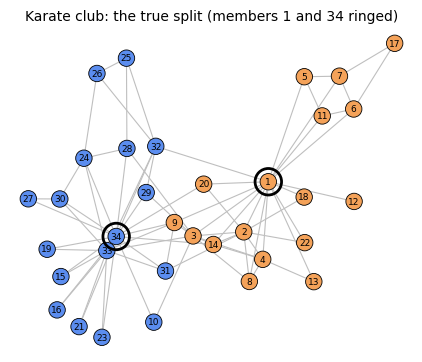

In [8]:
def spring_layout(A, steps=300, seed=3):
    """A small force-directed layout: linked nodes pull together, all nodes push apart."""
    rng = np.random.default_rng(seed)
    n = len(A)
    pos = rng.normal(size=(n, 2))
    k = 1.0 / np.sqrt(n)
    for t in range(steps):
        d = pos[:, None, :] - pos[None, :, :]
        dist = np.maximum(np.linalg.norm(d, axis=2), 1e-3)
        push = (k * k / dist ** 2)[:, :, None] * d
        pull = (A * dist / k)[:, :, None] * d
        move = (push - pull).sum(1)
        step = 0.1 * (1 - t / steps)
        pos += step * move / np.maximum(np.linalg.norm(move, axis=1, keepdims=True), 1e-9)
    pos -= pos.mean(0)
    return pos / np.abs(pos).max()

def draw_graph(ax, A, pos, colours, title, ring=None, size=140, labels=True):
    for i, j in zip(*np.where(np.triu(A) > 0)):
        ax.plot(pos[[i, j], 0], pos[[i, j], 1], color="0.75", lw=0.8, zorder=1)
    ax.scatter(pos[:, 0], pos[:, 1], c=colours, s=size, edgecolors="k", linewidths=0.6, zorder=2)
    if ring is not None:
        ax.scatter(pos[ring, 0], pos[ring, 1], s=size * 2.6, facecolors="none", edgecolors="k", linewidths=2, zorder=3)
    if labels:
        for i in range(len(A)):
            ax.text(pos[i, 0], pos[i, 1], str(i + 1), ha="center", va="center", fontsize=6.5, zorder=4)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

pos_k = spring_layout(A_k)
TWO = np.array(["#f4a259", "#5b8def"])
fig, ax = plt.subplots(figsize=(5.2, 4.2))
draw_graph(ax, A_k, pos_k, TWO[y_k], "Karate club: the true split (members 1 and 34 ringed)", ring=[0, 33])
plt.show()

### Why we see this

The average member has 156 / 34 = 4.59 friends in the club, and only 13.9% of the 561 possible pairs are
friends: like most real graphs this one is **sparse**. Two members are hubs. And 67 of the 78 friendships
(85.9%) join two people who ended up in the same club. Linked nodes tending to share a label is called
**homophily**, and it is the property that everything in Steps 9 to 12 relies on.

---
## Step 8 - A graph convolution layer, and a two-layer GCN

One GCN layer does two matrix products:

`H_new = activation( A_hat @ (H @ W + b) )`

`H @ W + b` is an ordinary `Dense` layer applied to every node's vector, with the same weights for every
node. `A_hat @ ...` then averages the results over each node's neighbourhood. The weights never see the
graph, so their number does not depend on how many nodes there are.

The model is **full-batch**: the whole graph is one input. It receives the feature matrix `X` of shape
`(nodes, features)` and the matrix `A_hat` of shape `(nodes, nodes)`, each with a batch dimension of 1 in
front, and returns one row of class scores per node.

The karate club has no node features. The standard trick is to give node i the i-th row of the identity
matrix: "I am member i" and nothing more. So `features = 34`.

> **Predict:** hidden width 16 and 2 classes. The first layer is a Dense from 34 to 16, the second from 16
> to 2. How many parameters? Does the 34 × 34 adjacency matrix add any?

In [9]:
class GraphConv(layers.Layer):
    """One graph convolution: a shared Dense on every node, then an average over neighbours."""
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.dense = layers.Dense(units)
        self.activation = keras.activations.get(activation)

    def call(self, x, a_hat):
        return self.activation(ops.matmul(a_hat, self.dense(x)))     # A_hat @ (X @ W + b)

def build_gcn(features, classes, hidden=16, depth=2, residual=False, dropout=0.5):
    """depth graph layers in all. Returns (model giving class scores, model giving the last hidden vectors)."""
    x_in = layers.Input(shape=(None, features), name="node_features")     # (nodes, features)
    a_in = layers.Input(shape=(None, None), name="a_hat")                 # (nodes, nodes)
    h = x_in
    for i in range(depth - 1):
        z = GraphConv(hidden, activation="relu")(layers.Dropout(dropout)(h), a_in)
        h = layers.Add()([h, z]) if (residual and i > 0) else z           # skip connection (Step 16)
        last_hidden = h
    scores = GraphConv(classes)(layers.Dropout(dropout)(h), a_in)
    return keras.Model([x_in, a_in], scores), keras.Model([x_in, a_in], last_hidden)

def gcn_params(features, classes, hidden=16, depth=2):
    sizes = [features] + [hidden] * (depth - 1) + [classes]
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))

X_k = np.eye(34, dtype="float32")              # featureless: one-hot identity of each member
Ah_k = norm_adj(A_k)

keras.utils.set_random_seed(SEED)
gcn_k, _ = build_gcn(features=34, classes=2)
print(f"{'layer':16s}{'output shape':20s}{'parameters':>10s}")
for layer in gcn_k.layers:
    print(f"{layer.name:16s}{str(tuple(layer.output.shape)):20s}{layer.count_params():10d}")
hand = (34 * 16 + 16) + (16 * 2 + 2)
print("hand count:", 34 * 16 + 16, "+", 16 * 2 + 2, "=", hand)
assert gcn_k.count_params() == hand == gcn_params(34, 2) == 594

out = gcn_k([X_k[None], Ah_k[None]])
print("X:", X_k[None].shape, " A_hat:", Ah_k[None].shape, " ->  scores:", tuple(out.shape))

layer           output shape        parameters
node_features   (None, None, 34)             0
dropout         (None, None, 34)             0
a_hat           (None, None, None)           0
graph_conv      (None, None, 16)           560
dropout_1       (None, None, 16)             0
graph_conv_1    (None, None, 2)             34
hand count: 560 + 34 = 594
X: (1, 34, 34)  A_hat: (1, 34, 34)  ->  scores: (1, 34, 2)


### Why we see this

34 · 16 + 16 = 560 for the first layer and 16 · 2 + 2 = 34 for the second: **594** parameters. The adjacency
matrix adds none. It is data, like the image is data for a CNN. (The 34 in the count comes from our choice of
one-hot features, not from the graph layer: Step 11's model has 16 real features and its count does not
mention the number of nodes at all.)

Shapes: `(1, 34, 34)` features and `(1, 34, 34)` adjacency go in, `(1, 34, 2)` comes out: two scores for each
of the 34 members, all computed in one pass.

---
## Step 9 - Train with two labels

We tell the model the club of exactly two members: the instructor (member 1) and the administrator
(member 34). The other 32 are unlabelled. They still take part in training, because their rows of `A_hat`
carry the messages; they do not contribute to the loss.

In Keras this is a per-node `sample_weight`: 1 for a labelled node, 0 for the rest (scaled so that the
printed loss is the mean over the labelled nodes). One epoch is one gradient step on the whole graph.

> **Predict:** two labels out of 34, and features that say nothing but "I am member i". How many of the
> other 32 members will the trained model put in the right club: about 16 (a coin), about 24, or 30 or more?

In [10]:
def fit_graph(model, X, A_hat, y, labelled, epochs=200, lr=0.01):
    """Full-batch training: the loss counts only the nodes where labelled == 1."""
    w = (labelled * len(y) / labelled.sum()).astype("float32")
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    hist = model.fit([X[None], A_hat[None]], y[None], sample_weight=w[None], epochs=epochs, verbose=0)
    return hist.history["loss"]

def predict_graph(model, X, A_hat):
    return model([X[None], A_hat[None]], training=False).numpy()[0]

def accuracy(model, X, A_hat, y, where):
    pred = predict_graph(model, X, A_hat).argmax(1)
    return float((pred == y)[where > 0].mean())

labelled_k = np.zeros(34, dtype="float32")
labelled_k[[0, 33]] = 1.0
unlabelled_k = 1.0 - labelled_k

keras.utils.set_random_seed(SEED)
gcn_k, _ = build_gcn(features=34, classes=2)

t0 = time.time()
loss_k = fit_graph(gcn_k, X_k, Ah_k, y_k, labelled_k, epochs=200)
pred_k = predict_graph(gcn_k, X_k, Ah_k).argmax(1)
wrong_k = [int(i) + 1 for i in np.where((pred_k != y_k) & (unlabelled_k > 0))[0]]
acc_k = accuracy(gcn_k, X_k, Ah_k, y_k, unlabelled_k)
print(f"loss: first epoch {loss_k[0]:.3f} (ln 2 = {np.log(2):.3f}), last epoch {loss_k[-1]:.3f}   [{time.time() - t0:.0f} s]")
print(f"GCN, 2 labels: {int(round(acc_k * 32))} of 32 unlabelled members right = {acc_k:.1%}")
print("members placed in the wrong club:", wrong_k)

loss: first epoch 0.635 (ln 2 = 0.693), last epoch 0.009   [8 s]
GCN, 2 labels: 31 of 32 unlabelled members right = 96.9%
members placed in the wrong club: [9]


---
## Step 10 - The same model with the edges taken away

Is the graph doing the work, or the Dense layers? Replace `A_hat` by the identity matrix. Then "average over
your neighbourhood" means "keep your own vector", and the GCN becomes an ordinary MLP applied to each node
separately, with the same 594 parameters.

> **Predict:** the MLP sees a one-hot row per member and has labels for members 1 and 34 only. What can it
> possibly know about member 17? What accuracy do you expect on the 32?

MLP (no edges), 2 labels: 20 of 32 right = 62.5%
GCN (with edges)        : 31 of 32 right = 96.9%
the two labelled members, MLP: [0 1]  truth: [0 1]


MLP with five other seeds, members right out of 32: [16, 21, 13, 14, 20] | mean 16.8 | a coin: 16


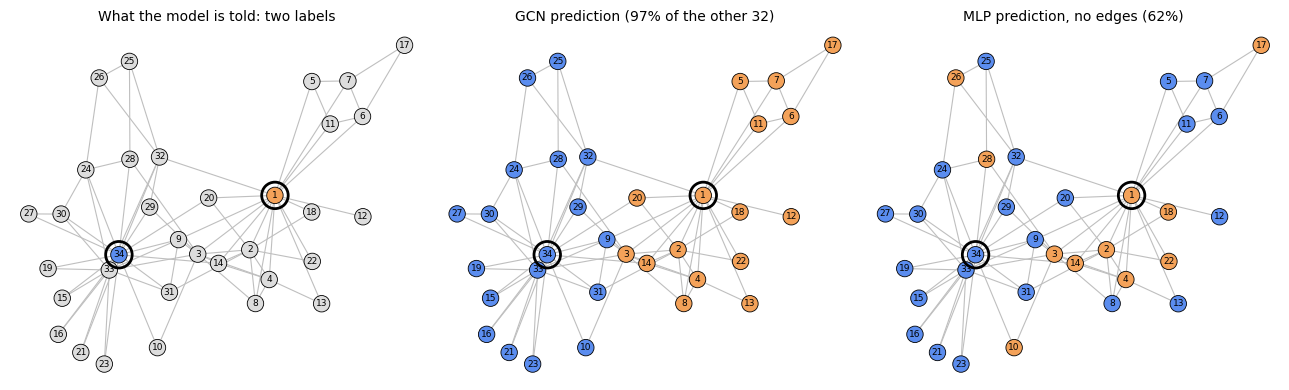

In [11]:
I_k = np.eye(34, dtype="float32")
keras.utils.set_random_seed(SEED)
mlp_k, _ = build_gcn(features=34, classes=2)
assert mlp_k.count_params() == 594
fit_graph(mlp_k, X_k, I_k, y_k, labelled_k, epochs=200)
acc_mlp_k = accuracy(mlp_k, X_k, I_k, y_k, unlabelled_k)
pred_mlp_k = predict_graph(mlp_k, X_k, I_k).argmax(1)
print(f"MLP (no edges), 2 labels: {int(round(acc_mlp_k * 32))} of 32 right = {acc_mlp_k:.1%}")
print(f"GCN (with edges)        : {int(round(acc_k * 32))} of 32 right = {acc_k:.1%}")
print("the two labelled members, MLP:", pred_mlp_k[[0, 33]], " truth:", y_k[[0, 33]])

mlp_seed_scores = []
for seed in range(1, 6):                       # the MLP's answer for the other 32 is luck: try five more seeds
    keras.utils.set_random_seed(seed)
    m, _ = build_gcn(features=34, classes=2)
    fit_graph(m, X_k, I_k, y_k, labelled_k, epochs=40)
    mlp_seed_scores.append(int(round(accuracy(m, X_k, I_k, y_k, unlabelled_k) * 32)))
print("MLP with five other seeds, members right out of 32:", mlp_seed_scores,
      "| mean", np.mean(mlp_seed_scores), "| a coin: 16")
keras.utils.set_random_seed(SEED)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
grey = np.array(["#dddddd"] * 34); grey[0] = TWO[0]; grey[33] = TWO[1]
draw_graph(axes[0], A_k, pos_k, grey, "What the model is told: two labels", ring=[0, 33])
draw_graph(axes[1], A_k, pos_k, TWO[pred_k], f"GCN prediction ({acc_k:.0%} of the other 32)", ring=[0, 33])
draw_graph(axes[2], A_k, pos_k, TWO[pred_mlp_k], f"MLP prediction, no edges ({acc_mlp_k:.0%})", ring=[0, 33])
plt.tight_layout(); plt.show()

### Why we see this

The MLP learns its two labelled rows perfectly and knows nothing about anyone else: the weights that belong
to member 17's one-hot input never receive a gradient, so its answer for member 17 is whatever the random
initial weights say. Its score on the 32 is luck: the five extra seeds scatter around a coin's 16.

The GCN had the same two labels and the same useless features. What it had in addition was the edges: the
label of member 1 flows to member 1's friends in the first layer and to their friends in the second, and the
same for member 34. With homophily, that is most of the answer. The one member it gets wrong, member 9, is
worth looking up in the drawing: it sits between the two groups, with friends 1 and 3 on one side and 31, 33
and 34 on the other. Zachary's own 1977 method also placed every member correctly except member 9.

This is **semi-supervised node classification**: few labels, and a graph that spreads them. It is also
**transductive**: the 32 unlabelled members were present, as nodes, during training.

---
## Step 11 - A bigger graph: three communities with weak features

The second graph is synthetic, from a **stochastic block model**: 600 nodes in three communities of 200. Two
nodes of the same community are linked with probability 0.03, two nodes of different communities with
probability 0.006. Each node also gets 16 feature numbers: its community's centre (a fixed direction of
length 1) plus Gaussian noise of standard deviation 1 in every coordinate. The noise is much larger than the
signal, so one node's features say little.

> **Predict:** a node has 199 possible same-community partners and 400 possible others. Roughly how many
> neighbours of each kind will it have? What fraction of edges will join two nodes of the same community?

In [12]:
K, N_PER, F = 3, 200, 16
P_IN, P_OUT, SIGNAL = 0.03, 0.006, 1.0
centres = np.random.default_rng(100).normal(size=(K, F))
centres /= np.linalg.norm(centres, axis=1, keepdims=True)        # three directions of length 1

def make_sbm(n_per, p_in, p_out, seed):
    """A stochastic block model with K communities and noisy features around the shared centres."""
    rng = np.random.default_rng(seed)
    y = np.repeat(np.arange(K), n_per).astype("int32")
    n = len(y)
    prob = np.where(y[:, None] == y[None, :], p_in, p_out)
    upper = np.triu(rng.random((n, n)) < prob, 1)                 # decide each pair once
    A = (upper | upper.T).astype("float32")
    X = (SIGNAL * centres[y] + rng.normal(size=(n, F))).astype("float32")
    return A, X, y

def homophily(A, y):
    return float((A * (y[:, None] == y[None, :])).sum() / A.sum())

A_s, X_s, y_s = make_sbm(N_PER, P_IN, P_OUT, seed=1)
N_S = len(y_s)
deg_s = A_s.sum(1)
print("nodes:", N_S, "| edges:", int(A_s.sum() / 2), "| features:", X_s.shape)
print(f"degree: mean {deg_s.mean():.2f}, min {int(deg_s.min())}, max {int(deg_s.max())}, isolated nodes {int((deg_s == 0).sum())}")
print(f"expected neighbours: {199 * P_IN:.2f} same community + {400 * P_OUT:.2f} other = {199 * P_IN + 400 * P_OUT:.2f}")
print(f"edges inside one community (homophily): {homophily(A_s, y_s):.1%}")
print("distance between two community centres:", np.round(np.linalg.norm(centres[0] - centres[1]), 2),
      "| noise std per coordinate: 1.0")

rng_split = np.random.default_rng(2)
labelled_s = np.zeros(N_S, dtype="float32")
for c in range(K):
    labelled_s[rng_split.choice(np.where(y_s == c)[0], 10, replace=False)] = 1.0
test_s = 1.0 - labelled_s
print("labelled nodes:", int(labelled_s.sum()), "(10 per community) | test nodes:", int(test_s.sum()))

nodes: 600 | edges: 2469 | features: (600, 16)
degree: mean 8.23, min 1, max 16, isolated nodes 0
expected neighbours: 5.97 same community + 2.40 other = 8.37
edges inside one community (homophily): 70.4%
distance between two community centres: 1.27 | noise std per coordinate: 1.0
labelled nodes: 30 (10 per community) | test nodes: 570


---
## Step 12 - GCN against MLP with 30 labels

Same recipe as the karate club, and the same settings for both models, fixed in advance: hidden width 16,
dropout 0.5, Adam at 0.01, 200 full-batch steps. The GCN gets `A_hat`. The MLP gets the identity matrix.

> **Predict:** the parameter count, with 16 features, 16 hidden units and 3 classes. Then: how much better
> than chance (33.3%) will the MLP do on features this noisy? And the GCN?

In [13]:
Ah_s = norm_adj(A_s)
I_s = np.eye(N_S, dtype="float32")
assert gcn_params(16, 3) == (16 * 16 + 16) + (16 * 3 + 3) == 323

def relative_spread(H):
    """Mean distance between two node vectors, divided by the mean length of a node vector."""
    H = H.astype("float64")
    sq = (H ** 2).sum(1)
    D = np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * H @ H.T, 0.0))
    return float(D[~np.eye(len(H), dtype=bool)].mean() / max(np.sqrt(sq).mean(), 1e-12))

def run(adj, depth=2, residual=False, X=X_s, y=y_s, labelled=labelled_s, seed=SEED):
    keras.utils.set_random_seed(seed)
    model, hidden_model = build_gcn(features=F, classes=K, depth=depth, residual=residual)
    assert model.count_params() == gcn_params(F, K, depth=depth)
    model.spread_before = relative_spread(predict_graph(hidden_model, X, adj))    # before any training
    t0 = time.time()
    loss = fit_graph(model, X, adj, y, labelled)
    return model, hidden_model, loss, time.time() - t0

gcn_s, gcn_s_hidden, loss_gcn, sec = run(Ah_s)
mlp_s, _, loss_mlp, _ = run(I_s)
acc_gcn_s = accuracy(gcn_s, X_s, Ah_s, y_s, test_s)
acc_mlp_s = accuracy(mlp_s, X_s, I_s, y_s, test_s)
print("parameters in each model:", gcn_s.count_params())
print(f"                  labelled 30    test 570      [{sec:.0f} s per run]")
print(f"GCN (with edges)    {accuracy(gcn_s, X_s, Ah_s, y_s, labelled_s):6.1%}      {acc_gcn_s:6.1%}")
print(f"MLP (no edges)      {accuracy(mlp_s, X_s, I_s, y_s, labelled_s):6.1%}      {acc_mlp_s:6.1%}")
print("chance: 33.3%")

parameters in each model: 323
                  labelled 30    test 570      [8 s per run]
GCN (with edges)    100.0%       86.5%
MLP (no edges)       93.3%       47.9%
chance: 33.3%


### Why we see this

The MLP fits its 30 labelled nodes well and then does only a little better than chance on the rest: with
30 examples in 16 noisy dimensions it has mostly memorised noise. The GCN has the same parameters and the
same 30 labels. Its advantage is that every node's vector is an average over a neighbourhood, and most of a
node's neighbours are from its own community. Averaging n noisy copies of the same signal cuts the noise by
about the square root of n. Two layers average over the neighbours' neighbours as well.

So the edges help twice: they **denoise the features**, and they **spread the few labels**.

Count check: 16 · 16 + 16 = 272 and 16 · 3 + 3 = 51, in all **323**, for a graph of 600 nodes. The number of
nodes is nowhere in the sum.

---
## Step 13 - When the edges say nothing

A graph network is only as good as the story its edges tell. Keep the same nodes, features and labels, and
replace the edges by random ones: every pair linked with the same probability, whatever the communities.

> **Predict:** with random edges, will the GCN be as good as the MLP, better, or worse? Think about what a
> node now averages over.

In [14]:
p_same_density = A_s.sum() / (N_S * (N_S - 1))
A_r, _, _ = make_sbm(N_PER, p_same_density, p_same_density, seed=7)      # edges ignore the communities
Ah_r = norm_adj(A_r)
gcn_r, _, _, _ = run(Ah_r)
acc_gcn_r = accuracy(gcn_r, X_s, Ah_r, y_s, test_s)
print(f"random graph: edges {int(A_r.sum() / 2)}, homophily {homophily(A_r, y_s):.1%}  (three equal groups: about 33%)")
print(f"GCN on the community graph : {acc_gcn_s:6.1%}")
print(f"MLP, no edges              : {acc_mlp_s:6.1%}")
print(f"GCN on the random graph    : {acc_gcn_r:6.1%}")

random graph: edges 2367, homophily 32.8%  (three equal groups: about 33%)
GCN on the community graph :  86.5%
MLP, no edges              :  47.9%
GCN on the random graph    :  41.4%


### Why we see this

On the random graph a node's neighbours come from all three communities in equal shares, so the average
washes the node's own weak signal out and puts nothing in its place. The GCN ends below the MLP that
ignored the edges altogether, and not far above chance.

Two lessons. First, always run the no-edges baseline: it tells you how much the graph is adding, and it can
be negative. Second, a GCN assumes homophily. On graphs where linked nodes tend to differ (buyers and
sellers, a fraudster and its victims) the plain average is the wrong aggregation.

---
## Step 14 - Over-smoothing, measured without any training

Each round of message passing is an average, and averages pull things together. To see the effect with no
network in the way, apply the mean matrix of Step 5 to the raw features again and again, and measure how
different the node vectors still are: the **mean distance between two nodes' vectors**, for pairs from
different communities and for pairs inside the same community.

> **Predict:** at round 0 the two distances are nearly equal (the features are mostly noise). What happens
> to each after 1 and 2 rounds? And after 32?

rounds   all pairs   same community   different communities   different / same
    0      5.71181       5.60384            5.76552               1.03
    1      2.05118       1.93640            2.10828               1.09
    2      1.03591       0.92108            1.09304               1.19
    4      0.38827       0.30793            0.42824               1.39
    8      0.08498       0.05631            0.09925               1.76
   16      0.00636       0.00370            0.00768               2.08
   32      0.00005       0.00003            0.00006               2.12
all-pairs distance after 16 rounds, as a fraction of round 0: 0.0011


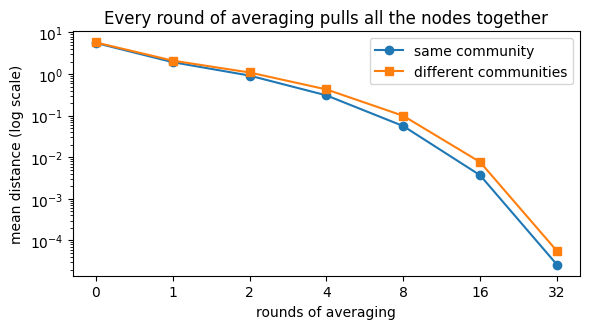

In [15]:
def pair_distances(H, y):
    """Mean distance between node vectors: (all pairs, same community, different communities)."""
    H = H.astype("float64")
    sq = (H ** 2).sum(1)
    D = np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * H @ H.T, 0.0))
    off = ~np.eye(len(H), dtype=bool)
    same = (y[:, None] == y[None, :]) & off
    diff = y[:, None] != y[None, :]
    return float(D[off].mean()), float(D[same].mean()), float(D[diff].mean())

P_s = mean_adj(A_s).astype("float64")
H = X_s.astype("float64")
smooth_rows = []
print("rounds   all pairs   same community   different communities   different / same")
k_done = 0
for k in [0, 1, 2, 4, 8, 16, 32]:
    while k_done < k:
        H = P_s @ H
        k_done += 1
    d_all, d_same, d_diff = pair_distances(H, y_s)
    smooth_rows.append((k, d_all, d_same, d_diff))
    print(f"  {k:3d}    {d_all:9.5f}     {d_same:9.5f}          {d_diff:9.5f}              {d_diff / d_same:5.2f}")
print(f"all-pairs distance after 16 rounds, as a fraction of round 0: {smooth_rows[5][1] / smooth_rows[0][1]:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ks = [r[0] for r in smooth_rows]
ax.plot(range(len(ks)), [r[2] for r in smooth_rows], "o-", label="same community")
ax.plot(range(len(ks)), [r[3] for r in smooth_rows], "s-", label="different communities")
ax.set_xticks(range(len(ks))); ax.set_xticklabels(ks)
ax.set_yscale("log")
ax.set_xlabel("rounds of averaging"); ax.set_ylabel("mean distance (log scale)")
ax.set_title("Every round of averaging pulls all the nodes together"); ax.legend()
plt.tight_layout(); plt.show()

### Why we see this

The first rounds are good news. Distances inside a community fall faster than distances between
communities, because a node is mostly averaging with its own kind, and the ratio in the last column climbs.
That is the denoising that made the GCN win in Step 12.

Now read the other columns. Every distance is shrinking, round after round, and fast: after 16 rounds two
nodes are about a thousand times closer than they were, and after 32 the 600 vectors agree to several
decimal places. A few edges cross between communities, and through them every community's average leaks into
the others, until all nodes hold the graph-wide average. This is **over-smoothing**.

The ratio says that the last difference to die is the one between communities. That is true and of little
use: a real layer adds noise of its own (dropout, a ReLU that zeroes half the values, new random weights),
and a difference in the fifth decimal place does not survive it. Depth in a graph network is reach (Step 6),
and too much reach means every node sees the whole graph and reports the same summary.

---
## Step 15 - Over-smoothing in trained networks: 2, 4, 8 and 16 layers

Now the GCN of Step 12 at four depths. Everything else is unchanged. For each we print the test accuracy
and how spread out the node vectors are in the last hidden layer: the mean distance between two nodes,
divided by the mean length of a node vector so that networks of different scale can be compared. The spread
is measured twice: on the freshly built network, before any training, and after training.

> **Predict:** in a CNN, more layers usually help (Chapter 17). Rank the four depths by test accuracy.

In [16]:
depth_rows = []
print("layers   params   labelled   test    spread before training   spread after   seconds")
for depth in [2, 4, 8, 16]:
    if depth == 2:
        model, hidden_model, used = gcn_s, gcn_s_hidden, sec
    else:
        model, hidden_model, _, used = run(Ah_s, depth=depth)
    Hd = predict_graph(hidden_model, X_s, Ah_s)
    row = (depth, model.count_params(), accuracy(model, X_s, Ah_s, y_s, labelled_s),
           accuracy(model, X_s, Ah_s, y_s, test_s), relative_spread(Hd), model.spread_before)
    depth_rows.append(row)
    print(f"  {row[0]:2d}     {row[1]:5,d}    {row[2]:6.1%}   {row[3]:6.1%}         {row[5]:6.3f}             {row[4]:6.3f}       {used:4.0f}")

layers   params   labelled   test    spread before training   spread after   seconds
   2       323    100.0%    86.5%          1.062              1.029          8


   4       867    100.0%    92.1%          0.415              0.958          8


   8     1,955     33.3%    33.5%          0.245              0.318          9


  16     4,131     36.7%    31.9%          0.184              0.167         12


---
## Step 16 - A skip connection for the deep ones

Chapter 17's cure for deep networks was the skip connection: add each layer's input to its output, so the
layer only has to learn a correction. In a graph network it has a second job: the node's own earlier vector
is carried forward untouched, so it cannot be averaged away completely.

> **Predict:** will a skip connection bring the 8-layer and 16-layer networks back to the 2-layer score,
> part of the way, or beyond it?

layers   plain test   with skips test   spread before training   spread after


   4        92.1%          90.0%               0.666               1.062


   8        33.5%          88.1%               0.287               1.030


  16        31.9%          59.3%               0.185               0.800


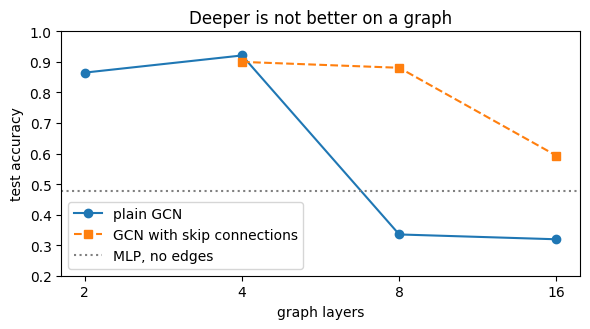

In [17]:
res_rows = []
print("layers   plain test   with skips test   spread before training   spread after")
for depth in [4, 8, 16]:
    model, hidden_model, _, _ = run(Ah_s, depth=depth, residual=True)
    Hd = predict_graph(hidden_model, X_s, Ah_s)
    plain = [r for r in depth_rows if r[0] == depth][0]
    row = (depth, plain[3], accuracy(model, X_s, Ah_s, y_s, test_s), relative_spread(Hd), model.spread_before)
    res_rows.append(row)
    print(f"  {row[0]:2d}       {row[1]:6.1%}         {row[2]:6.1%}              {row[4]:6.3f}              {row[3]:6.3f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(4), [r[3] for r in depth_rows], "o-", label="plain GCN")
ax.plot([1, 2, 3], [r[2] for r in res_rows], "s--", label="GCN with skip connections")
ax.axhline(acc_mlp_s, color="0.5", ls=":", label="MLP, no edges")
ax.set_xticks(range(4)); ax.set_xticklabels([2, 4, 8, 16]); ax.set_xlabel("graph layers")
ax.set_ylabel("test accuracy"); ax.set_ylim(0.2, 1.0); ax.legend(); ax.set_title("Deeper is not better on a graph")
plt.tight_layout(); plt.show()

### Why we see this

Read the two tables against Step 14.

**Before training**, the spread of the node vectors falls steadily with depth: 1.06, 0.42, 0.25, 0.18. No
learning is involved yet. That is over-smoothing as a property of the architecture.

**Training can fight it, up to a point.** The 4-layer network learnt weights that pulled its node vectors
apart again (0.96) and scored best here, 92.1% against 86.5% for two layers: two more rounds of averaging
cleaned these very noisy features a little further. (One split and one seed: treat 5.6 points as a hint.)
The 8-layer and 16-layer networks never left the starting line. They are right on about a third of their
own 30 labelled nodes, which is what one answer for everybody scores. Two causes are mixed in that failure:
the node vectors arrive at the last layer nearly alike, and a deep stack with dropout and without skips or
normalisation is hard to train in any case (Chapter 9).

**Skip connections** bring 8 layers back to 88.1% and 16 layers to 59.3%. Neither beats four plain layers.
That is the usual picture: most graph networks in use are 2 to 4 layers deep, and the deep ones need extra
machinery to be no worse.

---
## Step 17 - Shuffle the nodes: the predictions follow

The 600 nodes were listed community by community. That order is an accident of how we built the graph. Give
the nodes new numbers at random: row i of `X` moves to a new place, and the rows **and columns** of `A_hat`
move with it. It is the same graph.

> **Predict:** feed the renumbered graph to the trained GCN. Compared with the old predictions, the new ones
> are: unrelated, the same in the same rows, or the same but moved to the nodes' new rows?

In [18]:
perm = np.random.default_rng(5).permutation(N_S)
X_p = X_s[perm]
Ah_p = Ah_s[perm][:, perm]                     # move rows and columns together
out_original = predict_graph(gcn_s, X_s, Ah_s)
out_shuffled = predict_graph(gcn_s, X_p, Ah_p)
print("largest difference, shuffled output against original output moved the same way:",
      f"{np.abs(out_shuffled - out_original[perm]).max():.1e}")
print("largest difference if you forget to move the output:",
      f"{np.abs(out_shuffled - out_original).max():.2f}")
print("predicted classes agree for all nodes:", bool((out_shuffled.argmax(1) == out_original.argmax(1)[perm]).all()))

Ah_wrong = Ah_s[perm]                          # the bug: rows moved, columns forgotten
out_wrong = predict_graph(gcn_s, X_p, Ah_wrong)
print(f"rows moved but columns forgotten: test accuracy {float((out_wrong.argmax(1) == y_s[perm])[test_s[perm] > 0].mean()):.1%}")

largest difference, shuffled output against original output moved the same way: 9.5e-07
largest difference if you forget to move the output: 9.62
predicted classes agree for all nodes: True
rows moved but columns forgotten: test accuracy 31.6%


### Why we see this

The outputs are the old outputs in the new order, to within rounding. A graph layer is
**permutation-equivariant**: renumber the nodes and the answers are renumbered the same way, and nothing else
changes. It has to be so, because the layer only ever asks "who are my neighbours?", never "what is my row
number?". Chapter 34 showed the same property for attention without positions.

Take the mean of all the node vectors and even the renumbering disappears: that is a
**permutation-invariant** readout, used when the task is one answer for the whole graph.

The last line is a common data bug: the feature rows were reordered and the adjacency was not reordered to
match. The model runs, and the answers are rubbish.

---
## Step 18 - A graph the model has never seen

The weights of our GCN are a 16 × 16 matrix, a 16 × 3 matrix and two bias vectors. Nothing in them is tied
to these 600 nodes. So make a **new** graph from the same recipe: different random edges, different noise,
and 900 nodes this time. Run the trained model on it with no further training.

> **Predict:** will the model even accept a 900-node graph? If it does, will its accuracy be near the 600-node
> test score, or near chance?

In [19]:
A_new, X_new, y_new = make_sbm(300, P_IN * 2 / 3, P_OUT * 2 / 3, seed=11)   # same expected degree, 900 nodes
Ah_new = norm_adj(A_new)
everyone = np.ones(len(y_new), dtype="float32")
acc_new = accuracy(gcn_s, X_new, Ah_new, y_new, everyone)
acc_new_mlp = accuracy(mlp_s, X_new, np.eye(len(y_new), dtype="float32"), y_new, everyone)
print("new graph:", len(y_new), "nodes,", int(A_new.sum() / 2), "edges, mean degree", round(float(A_new.sum(1).mean()), 2))
print("parameters used:", gcn_s.count_params(), "(unchanged)")
print(f"GCN trained on the 600-node graph, run on the new one: {acc_new:.1%} of all 900 nodes")
print(f"MLP trained on the 600-node graph, run on the new one: {acc_new_mlp:.1%}")
print(f"(for reference, GCN test accuracy on its own graph: {acc_gcn_s:.1%})")

new graph: 900 nodes, 3880 edges, mean degree 8.62
parameters used: 323 (unchanged)
GCN trained on the 600-node graph, run on the new one: 84.4% of all 900 nodes
MLP trained on the 600-node graph, run on the new one: 47.0%
(for reference, GCN test accuracy on its own graph: 86.5%)


### Why we see this

The model accepts the new graph because its inputs are declared with `None` for the number of nodes, and its
weights act on feature vectors, not on node numbers. This is the **inductive** setting: learn on one graph,
predict on another. It works here because the new graph follows the same rules (same feature centres, same
sort of community structure) and because the nodes have real features.

The karate-club model of Step 9 could not do this. Its input was a one-hot "I am member i", and a new club
has no member i. Featureless, identity-input models are transductive by construction.

---
## Step 19 - The trap of the plain sum: hubs

Step 4 said the sum keeps the count. Here is the price. Take the karate club, start every member at 1, and
pass messages with the plain `A + I` (a sum) and with `A_hat` (normalised).

> **Predict:** member 34 has 17 friends. After one round of plain summing its value is 18. Roughly what is
> the largest value after 4 rounds: hundreds, thousands, or more?

In [20]:
S_k = A_k + np.eye(34, dtype="float32")
h_sum = np.ones(34, dtype="float32")
h_norm = np.ones(34, dtype="float32")
print("rounds   largest value, plain sum   largest value, normalised")
for k in range(1, 9):
    h_sum = S_k @ h_sum
    h_norm = Ah_k @ h_norm
    if k in (1, 2, 4, 8):
        print(f"  {k}        {h_sum.max():16,.0f}             {h_norm.max():8.3f}")

rounds   largest value, plain sum   largest value, normalised
  1                      18                2.003
  2                     102                1.620
  4                   6,492                1.681
  8              23,575,364                1.706


### Why we see this

With a plain sum, every round multiplies the values by roughly the degree, and the hubs feed each other. A
few layers in, the activations of well-connected nodes are thousands of times those of a member with one
friend, and training becomes unstable. The degree normalisation keeps every round's output on the scale of
its input. Layers that do sum on purpose (to keep the count) follow the sum with a normalisation layer or
an MLP that can rescale.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 9: label members 5 and 6 (both on the instructor's side, friends of each other) in place of 1 and 34 | Can a model learn two classes from labels of one class? | |
| 2 | Step 9: label members 12 and 27 (one friend and two friends) in place of the two hubs | How far does a label travel from a node with one edge in two layers? | |
| 3 | Step 8: `Ah_k = norm_adj(A_k, self_loops=False)` and retrain Step 9 | The two labelled nodes no longer hear themselves. Better or worse? | |
| 4 | Step 11: `SIGNAL = 2.0` | The features now say a lot. How much of the GCN's lead over the MLP survives? | |
| 5 | Step 11: `P_OUT = 0.015` (homophily near 50%) | Where does the GCN land between its Step 12 and Step 13 scores? | |
| 6 | Step 11: 2 labelled nodes per community in place of 10 | Which model loses more? | |
| 7 | Step 12: use `mean_adj(A_s)` in place of `norm_adj(A_s)` | Does the kind of normalisation matter on a graph without big hubs? | |
| 8 | Step 15: `dropout=0.0` in `build_gcn` for the 8-layer run | Was dropout part of the deep networks' trouble? | |

---
## Exercises

1. **A whole-graph task.** Make 200 small graphs of 30 nodes: half with two communities, half with one
   (same number of edges on average). Give every node the single feature 1. Add a mean readout
   (`ops.mean(h, axis=1)`) after the last graph layer and a `Dense(1)`, and classify the graphs. Then swap
   the mean readout for a sum. Which works, and why does one of them need the node degree as a feature?
2. **Link prediction and its leak.** Hide 10% of the karate club's edges. Train a GCN on the rest, score a
   pair of nodes by the dot product of their hidden vectors, and rank the hidden edges against the same
   number of non-edges. Then "forget" to remove the hidden edges from `A_hat` and score again. How much does
   the leak flatter the model?
3. **Attention on a graph.** Replace the fixed entries of `A_hat` with learnt weights: for each edge, a small
   Dense layer on the two end vectors gives a score, and a softmax over each node's neighbours turns scores
   into weights (GAT, 2017/18). Does it help on the random-edge graph of Step 13, where some neighbours
   deserve to be ignored?
4. **Neighbour sampling.** For each node keep at most 5 randomly chosen neighbours when building `A_hat`
   (GraphSAGE, 2017), drawing a new sample at every training step. How much accuracy is lost, and how much
   smaller is the largest row?
5. **Directed edges.** Make the toy graph directed (A → B, A → C, B → C, C → D, D → E) by filling only one
   triangle of the matrix. Who hears from whom after 3 rounds? What does symmetrising the matrix assume?
6. **Seeds.** Repeat Step 12 with five different seeds for the choice of labelled nodes. How large is the
   spread of the GCN's test accuracy, and of the MLP's? Would you trust a 2-point difference between two
   graph models on one split?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Graph | nodes + edges; node features `X` of shape (nodes, features); adjacency `A` of shape (nodes, nodes) |
| Degree | row sum of `A`; karate club: 34 nodes, 78 edges, mean degree 4.59, hubs 16 and 17 |
| Message passing | send, aggregate (sum, mean or max: order-free), update; one round = one hop |
| Mean / sum / max | mean forgets the count; max keeps only the largest; sum keeps the count and grows with degree |
| Self-loops | `A + I`, or a node's new vector ignores its old one |
| GCN matrix | `A_hat = D^(-1/2) (A + I) D^(-1/2)`, built once before training |
| GCN layer | `activation(A_hat @ (H @ W + b))`: a shared Dense, then a neighbourhood average |
| Parameters | in · out + out per layer, whatever the size of the graph: 594 (34 → 16 → 2), 323 (16 → 16 → 3) |
| Full-batch | the whole graph is one input: shapes (1, nodes, features) and (1, nodes, nodes) |
| Few labels | per-node `sample_weight` of 0 hides a node from the loss; it still passes messages |
| Baseline | the same model with `A_hat = I` is an MLP: always run it |
| Homophily | linked nodes share labels; without it the plain average hurts |
| Depth | k layers = k hops; too many layers over-smooth; 2 to 4 is usual; skips help |
| Equivariance | renumber the nodes (rows of X, rows and columns of A): outputs are renumbered the same way |
| Transductive / inductive | predict hidden nodes of the training graph / run on a new graph (needs real features) |

In [21]:
print(f"whole notebook: {time.time() - t_start:.0f} seconds")

whole notebook: 113 seconds
